# Gaussian Naive Bayes · Guess the Animal

A wildlife reserve sends us two measurements of an animal: **body mass** and **neck length**. We know it is an elephant, a giraffe, or a rhinoceros. How can we compare the three possibilities?

**Before you run the notebook.** The animal has a body mass of 1,500 kg and a neck length of 1.15 m. Which class would you pick based on mass alone? Would your answer change if you knew its neck length?

The data and distribution parameters are synthetic. To run every cell, use a Python Jupyter environment with NumPy, pandas, Matplotlib, and scikit-learn. The plots and results are already included in the notebook.

## 1. Define the distributions and generate data

For each animal class, we define two normal distributions $\mathcal N(\mu,\sigma^2)$. The table gives the mean $\mu$ and the standard deviation $\sigma$.

| Class | Body mass $\mu$ (kg) | Body mass $\sigma$ (kg) | Neck length $\mu$ (m) | Neck length $\sigma$ (m) |
| :-- | --: | --: | --: | --: |
| Elephant | 4500 | 650 | 0.80 | 0.16 |
| Giraffe | 1050 | 220 | 1.65 | 0.23 |
| Rhinoceros | 1700 | 350 | 0.65 | 0.15 |

Once we fix the class, we sample body mass and neck length **independently** for each animal. That makes the features **conditionally independent given the class**. With real measurements, we would need to justify that assumption.

The classifier uses the generated measurements and their class labels to estimate the distribution parameters from the training data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.naive_bayes import GaussianNB

rng = np.random.default_rng(42)
features = ["Body mass (kg)", "Neck length (m)"]
target = "Class"

# Each feature is specified as a (mean, standard deviation) pair.
distributions = {
    "Elephant": [(4500, 650), (0.80, 0.16)],
    "Giraffe": [(1050, 220), (1.65, 0.23)],
    "Rhinoceros": [(1700, 350), (0.65, 0.15)],
}
colors = {"Elephant": "#2463A6", "Giraffe": "#AD5400", "Rhinoceros": "#067B71"}

n_train = 600
n_test = 250
groups = []
for species, (mass_params, neck_params) in distributions.items():
    mass = rng.normal(*mass_params, size=n_train + n_test)
    neck = rng.normal(*neck_params, size=n_train + n_test)
    groups.append(pd.DataFrame({
        features[0]: mass,
        features[1]: neck,
        target: species,
    }))

train = pd.concat([group.iloc[:n_train] for group in groups], ignore_index=True)
test = pd.concat([group.iloc[n_train:] for group in groups], ignore_index=True)
display(train.sample(6, random_state=42).round(2).reset_index(drop=True))

,Body mass (kg),Neck length (m),Class
0,2242.05,0.56,Rhinoceros
1,882.04,1.50,Giraffe
2,1225.24,1.84,Giraffe
3,5883.51,0.72,Elephant
4,1593.88,0.67,Rhinoceros
5,3670.80,0.75,Elephant


## 2. Explore the data

The left plot shows all three classes. The right plot zooms in on the range where giraffe and rhinoceros body masses overlap. The star marks the animal from the opening question.

The correlations below are calculated from this sample. Within each class, they are close to zero because of how we generated the data. When we pool the classes, the features can become correlated because both of their distributions depend on the class.

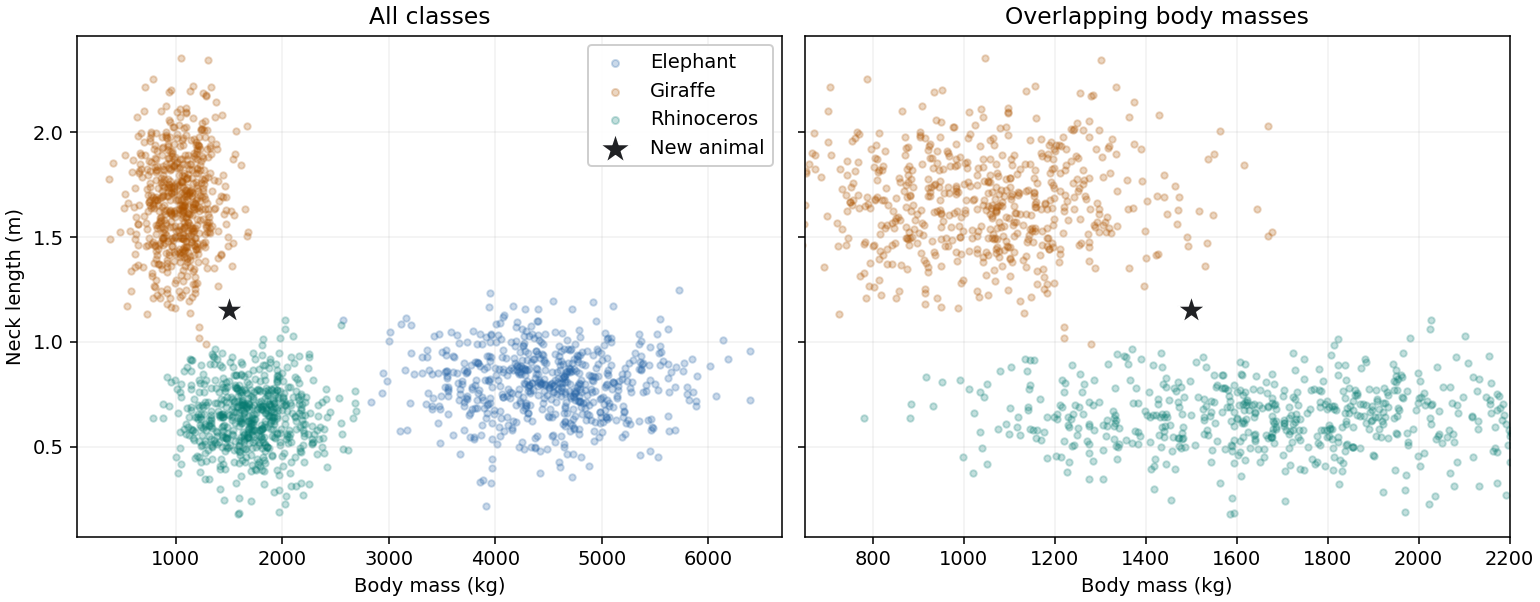

,Correlation between body mass and neck length
Elephant,-0.038
Giraffe,0.043
Rhinoceros,-0.013
All classes combined,-0.476


In [2]:
animal = pd.DataFrame([[1500, 1.15]], columns=features)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True, layout="constrained")
for ax in axes:
    for species, group in train.groupby(target, sort=False):
        ax.scatter(group[features[0]], group[features[1]], s=11, alpha=0.24,
                   color=colors[species], label=species)
    ax.scatter(*animal.iloc[0], marker="*", s=230, color="#202124",
               edgecolors="white", linewidths=0.8, label="New animal", zorder=5)
    ax.set_xlabel(features[0])
    ax.grid(alpha=0.17)
axes[0].set(title="All classes", ylabel=features[1])
axes[1].set(title="Overlapping body masses", xlim=(650, 2200))
axes[0].legend(loc="upper right", framealpha=0.95, markerscale=1.1)
plt.show()

correlations = {
    species: group[features[0]].corr(group[features[1]])
    for species, group in train.groupby(target, sort=False)
}
correlations["All classes combined"] = train[features[0]].corr(train[features[1]])
display(pd.Series(correlations, name="Correlation between body mass and neck length").round(3).to_frame())

## 3. Estimate parameters and plot the densities

For each class and feature, we calculate the mean and standard deviation. The class prior $P(C)$ is the proportion of training examples in class $C$. Here, all three classes occur equally often.

The histograms show the generated data. The curves are normal probability densities fitted to those data. Each dashed line marks one measurement of the new animal. The height of a curve at that point is a **density**. The probability of a measurement falling in an interval is the area under the curve over that interval.

Mean                 Std. deviation                
           Body mass (kg) Neck length (m) Body mass (kg) Neck length (m)
Class                                                                   
Elephant         4482.993           0.798        632.445           0.162
Giraffe          1032.512           1.665        217.021           0.230
Rhinoceros       1702.523           0.641        349.014           0.152

,Prior probability
Class,
Elephant,0.333
Giraffe,0.333
Rhinoceros,0.333


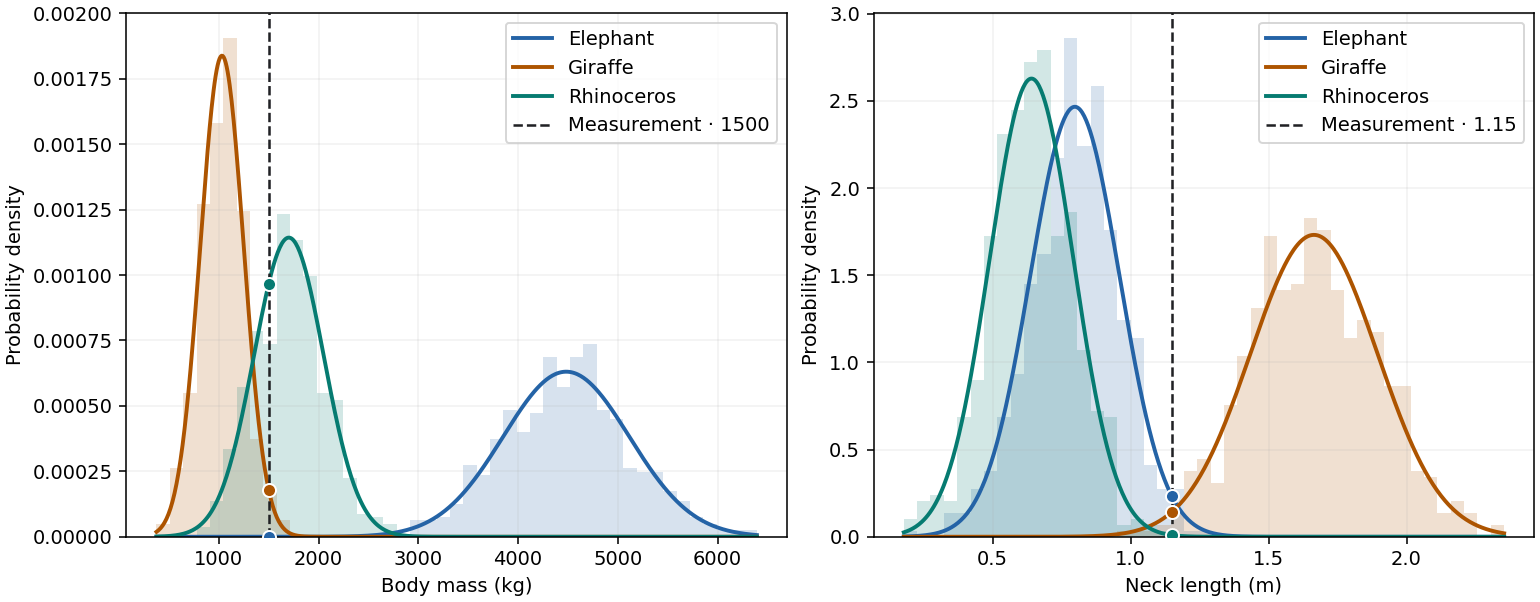

In [3]:
def normal_pdf(x, mean, std):
    z = (x - mean) / std
    return np.exp(-0.5 * z**2) / (std * np.sqrt(2 * np.pi))


by_species = train.groupby(target, sort=False)
means = by_species[features].mean()
stds = by_species[features].std(ddof=0)
priors = by_species.size() / len(train)

parameters = pd.concat({"Mean": means, "Std. deviation": stds}, axis=1)
display(parameters.round(3))
display(priors.rename("Prior probability").round(3).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), layout="constrained")
for ax, feature in zip(axes, features):
    observed = animal.at[0, feature]
    grid = np.linspace(train[feature].min(), train[feature].max(), 600)
    bins = np.linspace(grid.min(), grid.max(), 46)
    for species, group in by_species:
        color = colors[species]
        mean = means.at[species, feature]
        std = stds.at[species, feature]
        ax.hist(group[feature], bins=bins, density=True, color=color, alpha=0.18)
        ax.plot(grid, normal_pdf(grid, mean, std), color=color, lw=2, label=species)
        ax.scatter(observed, normal_pdf(observed, mean, std), color=color,
                   edgecolors="white", s=45, zorder=5)
    ax.axvline(observed, ls="--", color="#202124", lw=1.3, label=f"Measurement · {observed:g}")
    ax.set(xlabel=feature, ylabel="Probability density", ylim=(0, None))
    ax.grid(alpha=0.17)
    ax.legend()
plt.show()

## 4. Classify one animal by hand

Let $m$ be body mass, $\ell$ be neck length, and $C$ be the class. Conditional independence lets us multiply the two individual feature densities to get the joint density:

$$
p(m,\ell\mid C)=p(m\mid C)\,p(\ell\mid C).
$$

Using Bayes' rule, we first calculate an unnormalized score for each class. Then we divide each score by the sum of all three scores:

$$
s_C=P(C)\,p(m\mid C)\,p(\ell\mid C), \qquad
P(C\mid m,\ell)=\frac{s_C}{\sum_k s_k}.
$$

For comparison, we also classify the animal using **body mass alone**. In that case, the score for class $C$ is $P(C)\,p(m\mid C)$.

In [4]:
density = normal_pdf(animal.iloc[0], means, stds)
mass_score = priors * density[features[0]]
joint_score = priors * density.prod(axis=1)

posterior_mass = mass_score / mass_score.sum()
posterior_both = joint_score / joint_score.sum()

calculation = pd.DataFrame({
    "P(class)": priors,
    "p(mass | class)": density[features[0]],
    "p(neck length | class)": density[features[1]],
    "Score": joint_score,
    "P(class | mass)": posterior_mass,
    "P(class | both features)": posterior_both,
})
formats = {
    "P(class)": "{:.1%}",
    "p(mass | class)": "{:.3g}",
    "p(neck length | class)": "{:.3g}",
    "Score": "{:.3g}",
    "P(class | mass)": "{:.1%}",
    "P(class | both features)": "{:.1%}",
}
display(calculation.assign(**{
    column: calculation[column].map(pattern.format)
    for column, pattern in formats.items()
}))

print(f"Body mass alone → {posterior_mass.idxmax()}")
print(f"Both features → {posterior_both.idxmax()}")

,P(class),p(mass | class),p(neck length | class),Score,P(class | mass),P(class | both features)
Class,,,,,,
Elephant,33.3%,9.31e-09,0.232,7.2e-10,0.0%,0.0%
Giraffe,33.3%,0.000181,0.143,8.62e-06,15.8%,73.7%
Rhinoceros,33.3%,0.000966,0.00955,3.07e-06,84.2%,26.3%


Body mass alone → Rhinoceros
Both features → Giraffe


For the original measurements of 1,500 kg and 1.15 m, **rhinoceros** leads on body mass alone (84.2%). At 1.15 m, the giraffe's neck-length density is about 15 times the rhinoceros's. That is enough to change the prediction.

The giraffe's score is approximately $\frac{1}{3}\cdot 1.81\times10^{-4}\cdot 0.143 = 8.62\times10^{-6}$. Dividing this score by the sum of all three scores gives **73.7%**. The elephant has an even higher neck-length density at 1.15 m, but 1,500 kg is far from the center of its body-mass distribution.

## 5. Check the calculation with scikit-learn

We fit `GaussianNB` to the same data. All feature variances within each class are positive, so we can set `var_smoothing=0` to match the calculation by hand. The last line reports the fraction of correct predictions on a separately generated test set.

In [5]:
model = GaussianNB(var_smoothing=0)
model.fit(train[features], train[target])

sklearn_posterior = pd.Series(model.predict_proba(animal)[0], index=model.classes_)
np.testing.assert_allclose(
    sklearn_posterior.loc[posterior_both.index], posterior_both, rtol=1e-10
)

print("GaussianNB probabilities match the calculation by hand.")
print(f"GaussianNB prediction → {model.predict(animal)[0]}")
print(f"Test accuracy ({len(test)} animals) → "
      f"{model.score(test[features], test[target]):.1%}")

GaussianNB probabilities match the calculation by hand.
GaussianNB prediction → Giraffe
Test accuracy (750 animals) → 99.5%


### Discussion questions

1. Keep the body mass at 1,500 kg and set the neck length to 1.00 m in the cell that defines `animal`. Which class now has the highest probability when you use both features?
2. At the same body mass, find a neck length for which the model assigns nearly equal probabilities to giraffe and rhinoceros.
3. How would the formula change if body mass and neck length were dependent within a class? Discuss which density you would need to estimate.